In [157]:
%pip install numpy matplotlib scipy scikit-image

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


(294, 294)


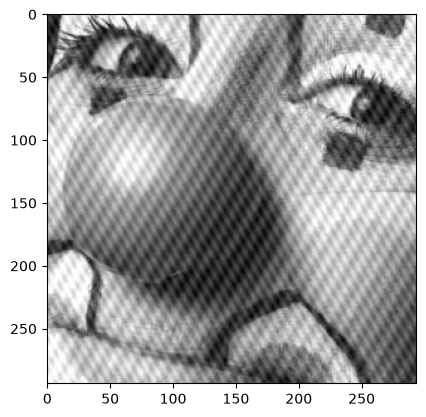

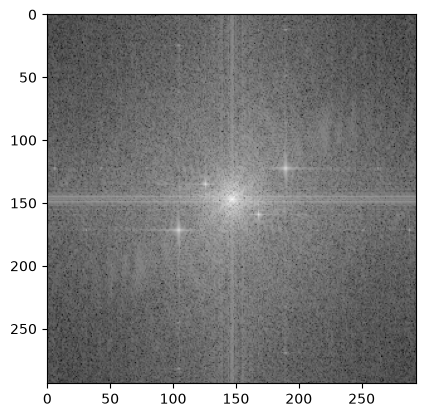

In [158]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as sp

image = plt.imread('clown.jpg')

#grayscale

image = np.mean(image, axis=2)
plt.imshow(image, cmap='gray')

print(image.shape)

fft = np.fft.fftshift(np.fft.fft2(image))
#plot fft
plt.figure()
plt.imshow(20*np.log(np.abs(fft)), cmap='gray', vmin=30, vmax=300)

In [159]:
def ShowImage(img, title='Image', cmap="gray", vmin=0, vmax=255):
    """
    Display an image using matplotlib.

    Parameters:
    img (numpy.ndarray): Image to be displayed.
    title (str): Title of the image display window.
    """
    plt.figure()
    plt.imshow(img, cmap=cmap, vmin=vmin, vmax=vmax)
    plt.title(title)
    plt.axis('off')
    plt.show()

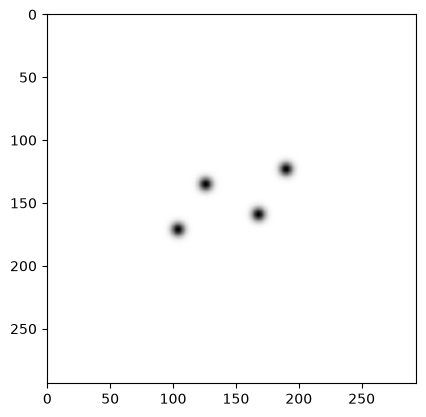

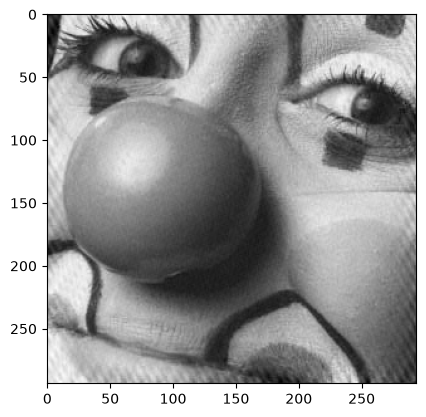

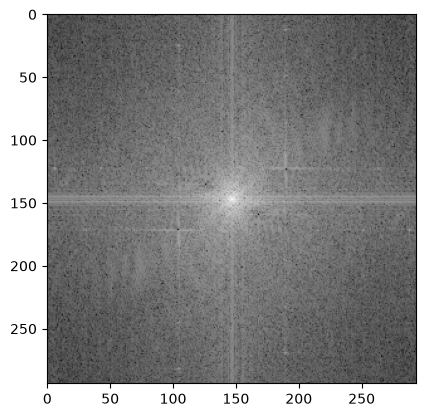

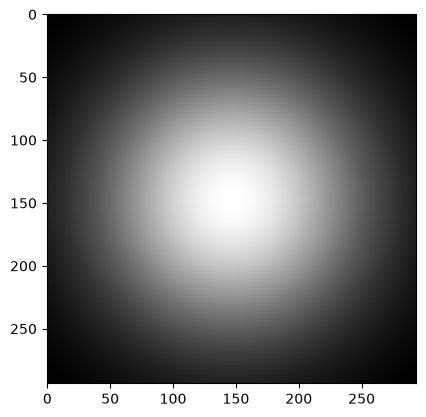

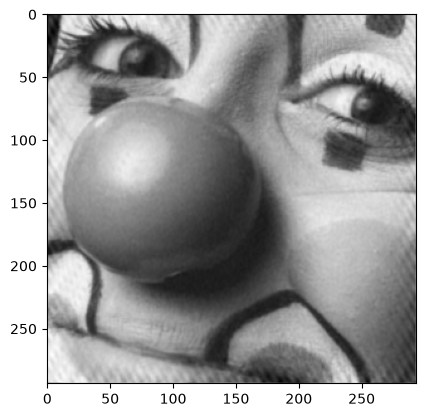

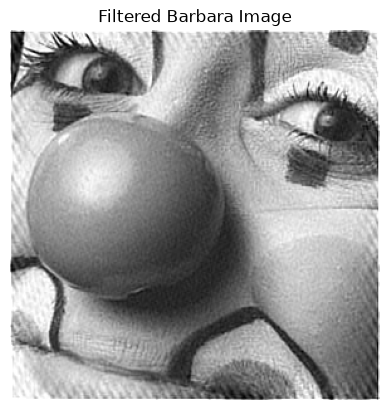

In [177]:
import numpy as np
import matplotlib.pyplot as plt
import skimage
from PIL import Image


# ============================================================
# Gaussian Notch Reject Filter
# ============================================================

def gaussian_notch_filter(shape, notch_frequencies, sigma=5):
    """
    Create a Gaussian notch-reject filter.

    Parameters
    ----------
    shape : tuple
        Image shape (rows, cols)

    notch_frequencies : list of (u, v)
        Frequencies to remove.
        Coordinates are relative to the CENTER of the FFT.

    sigma : float
        Width of each notch.

    Returns
    -------
    H : ndarray
        Notch filter in FFT-shifted coordinates.
    """

    rows, cols = shape

    u = np.arange(-cols // 2, cols // 2)
    v = np.arange(-rows // 2, rows // 2)

    U, V = np.meshgrid(u, v)

    H = np.ones(shape)

    for u0, v0 in notch_frequencies:

        # Distance to positive-frequency notch
        D1_squared = (
            (U - u0)**2 +
            (V - v0)**2
        )

        # Distance to symmetric negative-frequency notch
        D2_squared = (
            (U + u0)**2 +
            (V + v0)**2
        )

        # Gaussian notch pair
        notch = (
            1
            - np.exp(-D1_squared / (2 * sigma**2))
        )

        notch *= (
            1
            - np.exp(-D2_squared / (2 * sigma**2))
        )

        H *= notch

    return H

# ============================================================
# Gaussian Low-Pass Filter
# ============================================================

def gaussian_lowpass_filter(shape, D0):
    """
    Create a Gaussian low-pass filter.

    D0 controls the cutoff frequency.

    Smaller D0 -> stronger smoothing
    Larger D0  -> more high frequencies preserved
    """

    rows, cols = shape

    # Frequency coordinates centered at (0, 0)
    u = np.arange(-cols // 2, cols // 2)
    v = np.arange(-rows // 2, rows // 2)

    U, V = np.meshgrid(u, v)

    # Distance from frequency origin
    D = np.sqrt(U**2 + V**2)

    # Gaussian low-pass filter
    H = np.exp(
        -(D**2) / (2 * D0**2)
    )

    return H



# ============================================================
# Define interference frequencies
# ============================================================
notches = [
    (43, -24),
    (21, 12)
    #(43, -135),
    #(43, 123)
]


# ============================================================
# Create notch filter
# ============================================================

filter = gaussian_notch_filter(
    image.shape,
    notches,
    sigma=3.7
)


#filter fft
plt.figure()
#plt.imshow(20*np.log(np.abs(np.fft.fftshift(np.fft.fft2(filter)))), cmap='gray')
plt.imshow(filter, cmap='gray')

fft = np.fft.fftshift(np.fft.fft2(image))

filtered_image = np.fft.ifft2(np.fft.ifftshift(fft * filter)).real
plt.figure()
plt.imshow(np.abs(filtered_image), cmap='gray')

# print filtered fft
fft_filtered = np.fft.fftshift(np.fft.fft2(filtered_image))
plt.figure()
plt.imshow(20*np.log(np.abs(fft_filtered)), cmap='gray', vmin=30, vmax=300)


#low pass image

lowpass_filter = gaussian_lowpass_filter(image.shape, D0=75)
plt.figure()
plt.imshow(lowpass_filter, cmap='gray')

filtered_image = np.fft.ifft2(np.fft.ifftshift(fft * filter * lowpass_filter)).real

plt.figure()
plt.imshow(np.abs(filtered_image), cmap='gray')

def ApplyFilter(img, filter):
    return sp.convolve2d(img, filter, mode='same')

filter = np.array([
    [-0.1667, -0.6667, -0.1667],
    [-0.6667,  4.3333, -0.6667],
    [-0.1667, -0.6667, -0.1667]
])


filtered_barbara = ApplyFilter(filtered_image, filter)
ShowImage(filtered_barbara, 'Filtered Barbara Image')

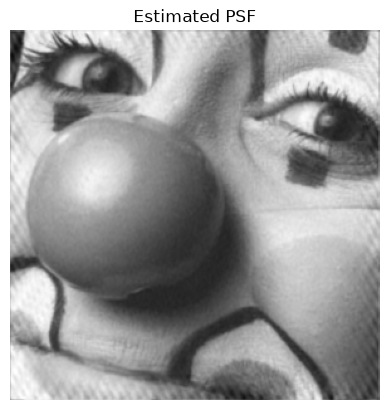

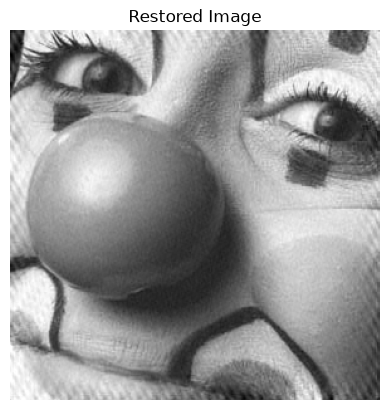

In [176]:
size = 25
sigma = 0.69

x = np.arange(-size // 2 + 1, size // 2 + 1)
X, Y = np.meshgrid(x, x)

psf = np.exp(-(X**2 + Y**2) / (2 * sigma**2))
psf /= psf.sum()

filtered_barbara2 = np.clip(filtered_image, 0, 255).astype(np.float64)/255

restored, estimated_psf = skimage.restoration.unsupervised_wiener(filtered_barbara2, psf)
ShowImage(filtered_barbara2, 'Estimated PSF', cmap='gray', vmin=0, vmax=1)
ShowImage(restored*255, 'Restored Image')